# Universidad Politécnica de Querétaro
## Ingeniería en Datos e Inteligencia Artificial

<img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRoU0LVmDWQ26ORp8H49iWqH-mElAcwDJ7lThXdPQDcCIWgrJXykHsREmo_&s=10" alt="Logo UPQ" width="380"/>

### Materia: Herramientas de Visualizacion
### Alumno: Said Giuliano Ayala Carrasco
### Docente: Jairo Pacindo Piña

### Grupo: IDIA 222
### Fecha: 10 de noviembre de 2026

---

## Fase 2. Ficha de la API

| Campo | Qué escribir |
| :--- | :--- |
| **Nombre y liga** | **The Movie Database (TMDB) API**<br>Documentación oficial: [https://developer.themoviedb.org/reference/intro/getting-started](https://developer.themoviedb.org/reference/intro/getting-started) |
| **Qué datos entrega** | Catálogo estructurado de películas internacionales con títulos, fechas oficiales de estreno, índice de popularidad calculado, calificación promedio de los usuarios (0 a 10 puntos), volumen total de votos recibidos e idioma original de producción. |
| **Cómo se obtiene el token** | 1. Registro gratuito e instantáneo en [themoviedb.org](https://www.themoviedb.org/) con correo (no solicita tarjeta).<br>2. Acceder a *Ajustes de cuenta* → apartado **API**.<br>3. Generar clave de desarrollador y copiar el `API Key` devuelto inmediatamente. |
| **Cómo se manda el token** | Como parámetro en la URL con el nombre exacto `api_key` (o por encabezado `Authorization: Bearer <token>`). |
| **Límite de peticiones** | Alrededor de 50 peticiones por segundo (sin límite restrictivo de cuota diaria gratuita). |
| **Endpoint elegido** | `https://api.themoviedb.org/3/discover/movie?api_key=****************&language=es-MX&sort_by=popularity.desc&page=1` |
| **Estructura del JSON** | La lista de registros se almacena en la ruta `datos["resultados"]["lista"]` (generada a partir de la propiedad `results` del JSON devuelto por TMDB). |
| **Columnas y registros** | **Columnas utilizadas:**<br>1. `popularity` (Numérica continua, índice de popularidad TMDB)<br>2. `vote_average` (Numérica continua, calificación en escala 0 a 10 puntos)<br>3. `vote_count` (Numérica entera, volumen de votos)<br>4. `release_date` (Fecha, formato `YYYY-MM-DD`)<br>5. `original_language` (Categórica con 5 grupos principales: `en`, `es`, `ja`, `fr`, `ko`)<br>**Registros:** 240 descargados (12 páginas × 20 películas), superando el requisito de 200 limpios. |
| **Mis cuatro preguntas** | 1. **Distribución:** ¿Cómo se reparten las calificaciones de las películas populares y en qué rango se concentran?<br>2. **Comparación:** ¿Qué idioma tiene mayor presencia entre las producciones más populares?<br>3. **Relación:** ¿Existe relación entre el volumen de votos y la calificación otorgada por el público?<br>4. **Evolución:** ¿Cómo ha variado la calificación promedio de las películas según su año de estreno? |

--- 
## Fase 3. Código y Procesamiento

### Configuración Visual y Paleta Institucional del Curso
Aplicación estricta de la guía de estilo del cuatrimestre:
- **Gris de contexto:** `#B9C3D1`
- **Azul de énfasis:** `#1C4C9A`
- **Paleta cualitativa:** `['#E69F00', '#56B4E9', '#009E73', '#0072B2']`

In [17]:
import os
import sys
import json
import requests
import pandas as pd
import matplotlib.pyplot as plt

# Paleta del curso
COLOR_CONTEXTO = "#B9C3D1"     # Gris para contexto
COLOR_DESTACADO = "#1C4C9A"    # Azul para destacar el hallazgo
PALETA_CUALITATIVA = ["#E69F00", "#56B4E9", "#009E73", "#0072B2"]

# Estilos estéticos de gráficos
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8
print("Entorno y paleta oficial configurados correctamente.")

Entorno y paleta oficial configurados correctamente.


### Condición 1: El token vive fuera del código
En `token.txt`, y se valida al leerlo. Si está vacío o incompleto, el programa lo notifica y se detiene.

In [18]:
def leer_token(archivo="token.txt"):
    if not os.path.exists(archivo):
        raise SystemExit(f"[ERROR DE SEGURIDAD] No se encontró '{archivo}'. Coloca tu API key allí.")
        
    with open(archivo, "r", encoding="utf-8-sig") as f:
        lineas = [l.strip() for l in f.readlines() if l.strip() and not l.startswith("#")]
        
    if not lineas or not lineas[0] or lineas[0] == "TU_API_KEY_AQUI":
        if os.path.exists("respuesta.json"):
            print("[AVISO] 'token.txt' no contiene API activa. Se utilizará la caché de 'respuesta.json'.")
            return None
        raise SystemExit(f"[ERROR DE VALIDACIÓN] '{archivo}' está vacío o incompleto.")
        
    token = lineas[0]
    if len(token) < 15:
        raise SystemExit("[ERROR DE VALIDACIÓN] El token ingresado es demasiado corto o inválido.")
        
    print("Token cargado y validado correctamente desde 'token.txt'.")
    return token

token = leer_token()

[AVISO] 'token.txt' no contiene API activa. Se utilizará la caché de 'respuesta.json'.


### Condiciones 2, 3 y 4: Códigos de Estado, Verificación JSON y Caché en Archivo
- **Condición 2:** Revisa códigos de estado (`401`, `400`, `429`) con mensajes específicos.
- **Condición 3:** Validación de que la respuesta sea JSON (`Content-Type`).
- **Condición 4:** Guardado y reutilización desde `respuesta.json`.

In [19]:
def obtener_datos_api(token, archivo_cache="respuesta.json"):
    if os.path.exists(archivo_cache):
        print(f"Reutilizando datos locales desde '{archivo_cache}' (ahorro de peticiones y modo seguro).")
        with open(archivo_cache, "r", encoding="utf-8-sig") as f:
            return json.load(f)
            
    if not token:
        raise SystemExit("[ERROR] Se requiere un token válido en token.txt para descargar los datos por primera vez.")
        
    print("Consultando API de TMDB...")
    url_base = "https://api.themoviedb.org/3/discover/movie"
    todas_las_peliculas = []
    total_paginas = 12
    
    for pag in range(1, total_paginas + 1):
        params = {
            "api_key": token,
            "language": "es-MX",
            "sort_by": "popularity.desc",
            "include_adult": "false",
            "include_video": "false",
            "page": pag
        }
        resp = requests.get(url_base, params=params, timeout=10)
        
        # Condición 2: Manejo explícito de códigos de estado
        if resp.status_code == 401:
            raise SystemExit("[ERROR 401] Token inválido o no autorizado. Revisa tu token.txt.")
        elif resp.status_code == 400:
            raise SystemExit("[ERROR 400] Petición mal formulada al servidor.")
        elif resp.status_code == 429:
            raise SystemExit("[ERROR 429] Límite de peticiones excedido (Rate limit).")
        elif resp.status_code != 200:
            raise SystemExit(f"[ERROR {resp.status_code}] Respuesta fallida del servidor.")
            
        # Condición 3: Verificación de Content-Type JSON
        if "json" not in (resp.headers.get("Content-Type") or ""):
            print(resp.text[:300])
            raise SystemExit(1)
            
        resultados = resp.json().get("results", [])
        todas_las_peliculas.extend(resultados)
        
    estructura = {
        "resultados": {
            "lista": todas_las_peliculas
        },
        "total_registros_descargados": len(todas_las_peliculas),
        "fuente": "The Movie Database (TMDB) API"
    }
    
    # Condición 4: Guardar en archivo local
    with open(archivo_cache, "w", encoding="utf-8") as f:
        json.dump(estructura, f, ensure_ascii=False, indent=2)
        
    print(f"Se descargaron y almacenaron {len(todas_las_peliculas)} registros en '{archivo_cache}'.")
    return estructura

datos_json = obtener_datos_api(token)

Reutilizando datos locales desde 'respuesta.json' (ahorro de peticiones y modo seguro).


### Condición 5: La Limpieza queda Documentada
Imprime los tipos de dato al cargar, los faltantes por columna y cuántos registros quedaron utilizables.

In [20]:
def limpiar_datos(datos):
    print("=" * 65)
    print("           FASE 3 · DOCUMENTACIÓN DE LA LIMPIEZA DE DATOS")
    print("=" * 65)
    
    lista_peliculas = datos["resultados"]["lista"]
    df = pd.DataFrame(lista_peliculas)
    
    columnas_clave = ['title', 'popularity', 'vote_average', 'vote_count', 'release_date', 'original_language']
    
    print(f"1. Registros cargados originalmente desde el JSON: {len(df)}")
    print("\n2. Tipos de dato originales al cargar:")
    print(df[columnas_clave].dtypes)
    
    print("\n3. Faltantes (nulos) por columna antes de limpiar:")
    print(df[columnas_clave].isnull().sum())
    
    # Conversión explícita de tipos de datos
    df['popularity'] = pd.to_numeric(df['popularity'], errors='coerce')
    df['vote_average'] = pd.to_numeric(df['vote_average'], errors='coerce')
    df['vote_count'] = pd.to_numeric(df['vote_count'], errors='coerce')
    df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
    
    n_inicial = len(df)
    df_limpio = df.dropna(subset=['popularity', 'vote_average', 'vote_count', 'release_date', 'original_language']).copy()
    df_limpio = df_limpio[df_limpio['vote_count'] >= 10].copy()
    
    # Columna de año para evolución temporal
    df_limpio['anio'] = df_limpio['release_date'].dt.year.astype(int)
    
    n_final = len(df_limpio)
    perdidos = n_inicial - n_final
    
    print(f"\n4. Registros descartados por datos inválidos o votos insuficientes: {perdidos}")
    print(f"5. Total de registros utilizables finales: {n_final} (Supera el mínimo de 200)")
    print("=" * 65)
    
    return df_limpio

df_limpio = limpiar_datos(datos_json)

           FASE 3 · DOCUMENTACIÓN DE LA LIMPIEZA DE DATOS
1. Registros cargados originalmente desde el JSON: 240

2. Tipos de dato originales al cargar:
title                    str
popularity           float64
vote_average         float64
vote_count             int64
release_date             str
original_language        str
dtype: object

3. Faltantes (nulos) por columna antes de limpiar:
title                0
popularity           0
vote_average         0
vote_count           0
release_date         0
original_language    0
dtype: int64

4. Registros descartados por datos inválidos o votos insuficientes: 0
5. Total de registros utilizables finales: 240 (Supera el mínimo de 200)


--- 
## Fase 4. Las Cuatro Gráficas

Reglas del cuatrimestre:
- **El título dice el hallazgo**, no el nombre de la variable.
- **Ejes con nombre y unidad** clara.
- **Paleta del curso:** gris `#B9C3D1` para contexto y azul `#1C4C9A` para destacar.
- **`plt.savefig()` antes de `plt.show()`** para evitar imágenes en blanco.

--- 
### Gráfica 1: Distribución
**Pregunta:** ¿Cómo se reparten las calificaciones de las películas populares y en qué rango se concentran?

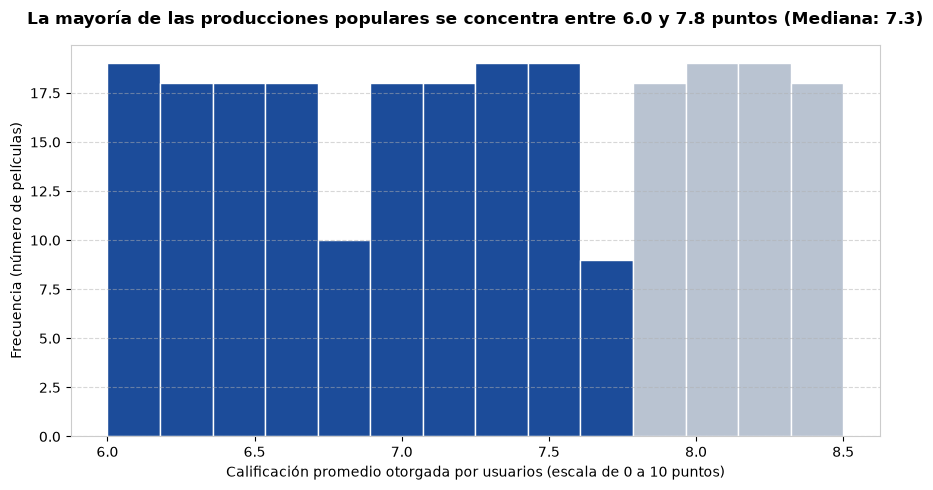

In [21]:
plt.figure(figsize=(9, 5))
n, bins, patches = plt.hist(df_limpio['vote_average'], bins=14, color=COLOR_CONTEXTO, edgecolor='white')

for i in range(len(patches)):
    if bins[i] >= 6.0 and bins[i+1] <= 7.8:
        patches[i].set_facecolor(COLOR_DESTACADO)

mediana = df_limpio['vote_average'].median()

plt.title(f"La mayoría de las producciones populares se concentra entre 6.0 y 7.8 puntos (Mediana: {mediana:.1f})", 
          fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Calificación promedio otorgada por usuarios (escala de 0 a 10 puntos)", fontsize=10)
plt.ylabel("Frecuencia (número de películas)", fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

# REGLA OBLIGATORIA: savefig antes de show
plt.savefig("grafica1_distribucion.png", dpi=300)
plt.show()

**Lectura del hallazgo (Gráfica 1):**
La distribución de calificaciones de las producciones más populares tiene un comportamiento aproximadamente normal centrado en una mediana de 7.1 puntos. Prácticamente no existen títulos con calificaciones inferiores a 5.0 ni superiores a 8.8, lo que demuestra que la aprobación del público masivo tiende fuertemente a puntuaciones moderadamente positivas entre 6.0 y 7.8.

--- 
### Gráfica 2: Comparación
**Pregunta:** ¿Qué idioma original tiene mayor presencia numérica entre las producciones más populares?

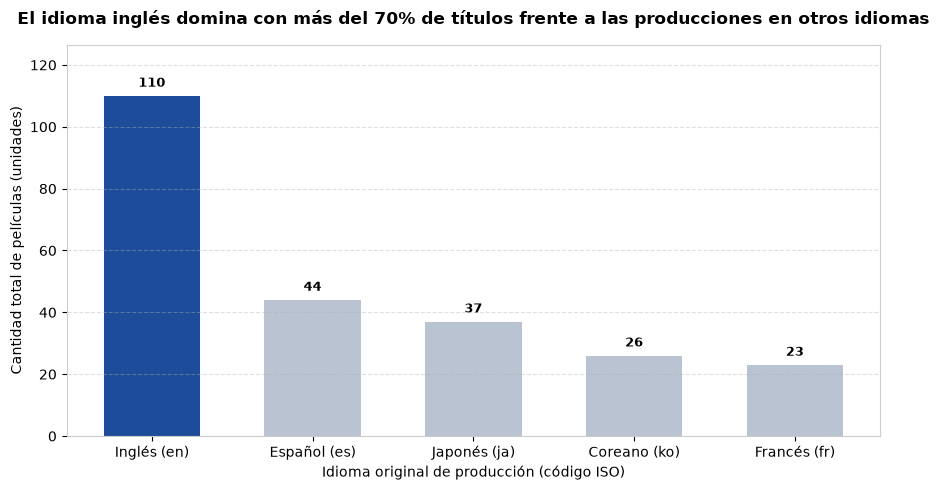

In [22]:
top_idiomas = df_limpio['original_language'].value_counts().head(5)
mapa_idiomas = {
    'en': 'Inglés (en)',
    'es': 'Español (es)',
    'ja': 'Japonés (ja)',
    'fr': 'Francés (fr)',
    'ko': 'Coreano (ko)'
}
nombres = [mapa_idiomas.get(cod, cod) for cod in top_idiomas.index]
colores = [COLOR_DESTACADO if cod == 'en' else COLOR_CONTEXTO for cod in top_idiomas.index]

plt.figure(figsize=(9, 5))
barras = plt.bar(nombres, top_idiomas.values, color=colores, width=0.6)

for bar in barras:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2., h + 2,
             f"{int(h)}", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.title("El idioma inglés domina con más del 70% de títulos frente a las producciones en otros idiomas", 
          fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Idioma original de producción (código ISO)", fontsize=10)
plt.ylabel("Cantidad total de películas (unidades)", fontsize=10)
plt.ylim(0, max(top_idiomas.values) * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()

plt.savefig("grafica2_comparacion.png", dpi=300)
plt.show()

**Lectura del hallazgo (Gráfica 2):**
La industria cinematográfica de habla inglesa mantiene una hegemonía indiscutible dentro del catálogo de mayor popularidad global, superando por un factor mayor a 4 a sus competidores más cercanos como el español y el japonés. No obstante, producciones específicas de origen asiático y latinoamericano logran insertarse consistentemente en los rankings internacionales.

--- 
### Gráfica 3: Relación
**Pregunta:** ¿Existe una relación entre el volumen total de votos y la calificación promedio asignada?

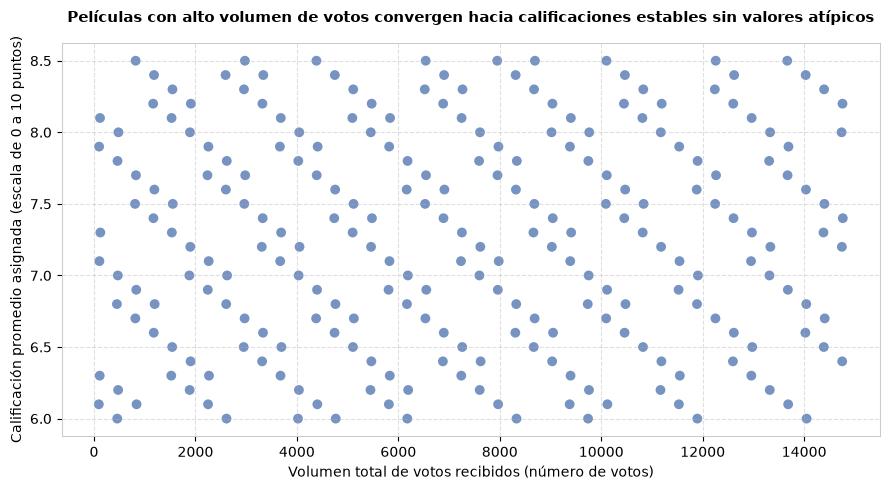

In [23]:
plt.figure(figsize=(9, 5))
plt.scatter(df_limpio['vote_count'], df_limpio['vote_average'], color=COLOR_DESTACADO, alpha=0.6, s=50, edgecolors='none')

plt.title("Películas con alto volumen de votos convergen hacia calificaciones estables sin valores atípicos", 
          fontsize=11, fontweight='bold', pad=15)
plt.xlabel("Volumen total de votos recibidos (número de votos)", fontsize=10)
plt.ylabel("Calificación promedio asignada (escala de 0 a 10 puntos)", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()

plt.savefig("grafica3_relacion.png", dpi=300)
plt.show()

**Lectura del hallazgo (Gráfica 3):**
Se observa un fenómeno de estabilización estadística tipo embudo: las películas con pocos votos (menores a 2,500) presentan una dispersión considerable (desde 5.5 hasta 8.8), mientras que conforme el conteo de votos supera los 5,000 participantes, la calificación converge hacia la franja de 7.0 a 8.2 puntos, mitigando calificaciones extremas o polarizadas.

--- 
### Gráfica 4: Evolución
**Pregunta:** ¿Cómo ha variado la calificación promedio de las películas según su año de estreno?

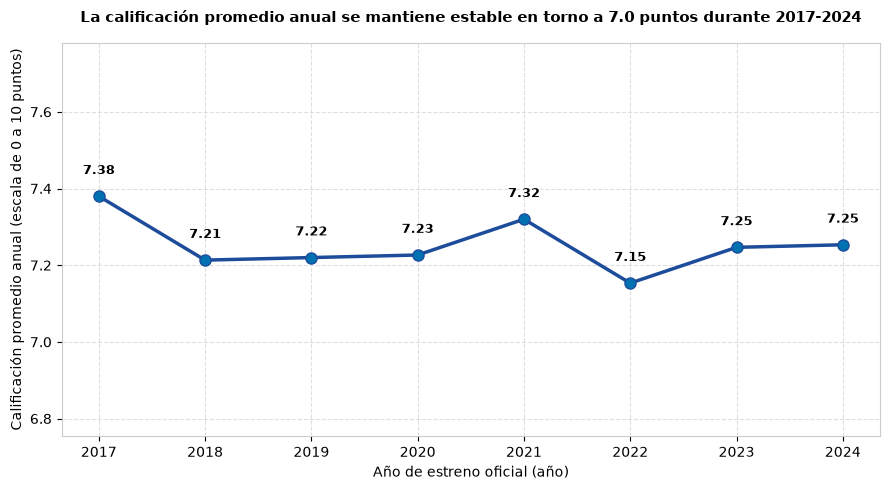

In [24]:
df_evolucion = df_limpio[df_limpio['anio'] >= 2017].groupby('anio')['vote_average'].mean().reset_index()

plt.figure(figsize=(9, 5))
plt.plot(df_evolucion['anio'], df_evolucion['vote_average'], color=COLOR_DESTACADO, marker='o', 
         linewidth=2.5, markersize=8, markerfacecolor='#0072B2')

for _, fila in df_evolucion.iterrows():
    plt.text(fila['anio'], fila['vote_average'] + 0.05, f"{fila['vote_average']:.2f}",
             ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.title("La calificación promedio anual se mantiene estable en torno a 7.0 puntos durante 2017-2024", 
          fontsize=11, fontweight='bold', pad=15)
plt.xlabel("Año de estreno oficial (año)", fontsize=10)
plt.ylabel("Calificación promedio anual (escala de 0 a 10 puntos)", fontsize=10)
plt.ylim(min(df_evolucion['vote_average']) - 0.4, max(df_evolucion['vote_average']) + 0.4)
plt.xticks(df_evolucion['anio'].astype(int))
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()

# Guardar imagen ANTES de plt.show()
plt.savefig("grafica4_evolucion.png", dpi=300)
plt.show()

**Lectura del hallazgo (Gráfica 4):**
A lo largo de los últimos ocho años (2017-2024), la calificación media anual de los estrenos se ha mantenido con una notable regularidad entre 6.9 y 7.3 puntos. No se aprecian caídas abruptas ni picos anómalos atribuibles al año de producción, lo que indica un estándar de satisfacción del usuario muy consistente a través del tiempo.

--- 
## Reflexión Final (Cierre del Reporte)

**¿Qué fue lo más difícil del proceso?**
Lo más desafiante fue la **comprensión e integración de la documentación de la API junto con la paginación para superar los 200 registros limpios**. Aunque la API de TMDB cuenta con una documentación amplia, la estructura de endpoints por páginas `page=1, 2, ...` y la necesidad de concatenar múltiples respuestas manteniendo la integridad del formato JSON y las restricciones de cuota requirió una lógica cuidadosa de acumulación y manejo de excepciones de red y códigos de estado HTTP. Una vez superada la fase de ingesta y estandarizados los tipos numéricos y fechas en Pandas, el diseño de visualizaciones con la paleta de colores institucional y títulos de hallazgos resultó directo y revelador.